# Exportação do Nordeste antes e depois de 15/08/2023

**Projeto Integrador — Saulo José da Silva Filho**

## 1. Pergunta e contexto

Em 15/08/2023, às 08h31, uma ocorrência de grande porte no SIN interrompeu o fornecimento de energia em várias regiões do país. O Nordeste é exportador líquido de energia, principalmente pela geração eólica e solar.

**Pergunta.** A exportação do Nordeste mudou depois do evento? Em particular, o teto observado da exportação ficou mais baixo e, se ficou, quando voltou ao nível anterior?

**Base.** Balanço de Energia nos Subsistemas (ONS), dados horários de 2023 a 2025.

## 2. Importação dos dados

In [12]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Caminho relativo à pasta deste notebook; os arquivos brutos não são alterados.
PASTA_DADOS = Path("dados brutos")
ANOS = [2023, 2024, 2025]

# Aparência dos gráficos
COR_TEXTO, COR_SECUNDARIA, COR_MUDA = "#0b0b0b", "#52514e", "#898781"
COR_GRADE, COR_EIXO, COR_FUNDO = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110,
    "figure.facecolor": COR_FUNDO, "axes.facecolor": COR_FUNDO,
    "axes.grid": True, "grid.color": COR_GRADE, "grid.linewidth": 0.6,
    "axes.edgecolor": COR_EIXO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": COR_SECUNDARIA, "xtick.color": COR_MUDA, "ytick.color": COR_MUDA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "text.color": COR_TEXTO, "font.size": 10,
})
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")

In [13]:
arquivos = [PASTA_DADOS / f"BALANCO_ENERGIA_SUBSISTEMA_{ano}.csv" for ano in ANOS]
bruto = pd.concat([pd.read_csv(a, sep=";") for a in arquivos], ignore_index=True)
bruto["din_instante"] = pd.to_datetime(bruto["din_instante"])

print(f"Linhas: {len(bruto):,} | Colunas: {bruto.shape[1]}")
print(f"Período: {bruto['din_instante'].min()} a {bruto['din_instante'].max()}")
bruto.head()

Linhas: 131,520 | Colunas: 9
Período: 2023-01-01 00:00:00 a 2025-12-31 23:00:00


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2023-01-01,"3,874.1",677.1,"13,305.3",1.9,"10,455.8","7,402.5"
1,N,NORTE,2023-01-01,"7,858.7",877.9,211.8,0.0,"5,990.6","2,957.8"
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01,"39,057.3","5,698.3","14,138.8",21.2,"58,904.1",11.5
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01,"24,661.1","4,071.6",6.0,18.2,"32,183.9","-3,427.0"
4,S,SUL,2023-01-01,"2,663.4",71.8,615.7,1.0,"10,273.8","-6,921.9"


## 3. Descrição da base

Cada linha é **uma hora de um subsistema**. A chave é `id_subsistema` + `din_instante`. Os valores estão em MWmed.

| Variável | Descrição |
|---|---|
| `id_subsistema`, `nom_subsistema` | Código e nome: N, NE, S, SE e o agregado SIN |
| `din_instante` | Data e hora de referência |
| `val_gerhidraulica` | Geração hidráulica verificada |
| `val_gertermica` | Geração térmica verificada |
| `val_gereolica` | Geração eólica verificada |
| `val_gersolar` | Geração fotovoltaica verificada |
| `val_carga` | Carga verificada |
| `val_intercambio` | Intercâmbio líquido verificado |

In [14]:
COLUNAS_GERACAO = ["val_gerhidraulica", "val_gertermica", "val_gereolica", "val_gersolar"]
COLUNAS_VALOR = COLUNAS_GERACAO + ["val_carga", "val_intercambio"]

print(bruto.dtypes, end="\n\n")
bruto.groupby("id_subsistema")[COLUNAS_VALOR].describe().T.loc[(slice(None), ["min", "50%", "max"]), :]

id_subsistema                   str
nom_subsistema                  str
din_instante         datetime64[us]
val_gerhidraulica           float64
val_gertermica              float64
val_gereolica               float64
val_gersolar                float64
val_carga                   float64
val_intercambio             float64
dtype: object



id_subsistema                N       NE        S        SE       SIN
val_gerhidraulica min    275.3  1,186.9    814.2  12,361.2  20,915.4
                  50%  5,669.7  3,094.5  9,769.5  27,778.5  48,303.5
                  max 19,532.7  8,323.8 15,835.0  48,893.1  87,875.7
val_gertermica    min    155.5    134.8     19.0   2,194.0   4,415.9
                  50%  1,581.0    426.5  1,050.8   5,758.2   8,862.2
                  max  3,589.3  3,741.9  2,153.6  12,525.1  19,869.3
val_gereolica     min      0.0    394.9     15.0       0.0     540.9
                  50%    210.9 11,171.2    617.1       7.0  12,063.9
                  max    418.0 22,681.5  2,065.2     265.0  25,064.8
val_gersolar      min      0.0      0.0      0.0       0.0       0.0
                  50%      5.1    267.7      2.5     326.2     888.4
                  max  2,438.8 13,834.6  6,950.8  21,933.9  42,551.7
val_carga         min  1,364.3  7,262.3  6,439.2  26,260.2  46,389.8
                  50%  7,753.9 12,878.5 13,412.5  43,590.4  77,636.3
                  max 10,239.2 18,157.0 22,737.4  62,149.9 106,148.7
val_intercambio   min -4,535.0 -7,872.6 -9,760.3 -16,172.0  -2,701.3
                  50%    452.4  5,748.7   -945.2  -5,908.0       0.0
                  max 14,146.5 13,591.5  7,722.6   6,116.4   2,700.8

## 4. Diagnóstico de qualidade

Verificações feitas antes de qualquer tratamento: valores ausentes, duplicidade da chave, lacunas na série horária, valores negativos, relação do SIN com os subsistemas, sinal do intercâmbio, zeros da solar e valores extremos.

In [15]:
horas_esperadas = len(pd.date_range(bruto["din_instante"].min(), bruto["din_instante"].max(), freq="h"))

diagnostico = bruto.groupby("id_subsistema").agg(
    linhas=("din_instante", "size"),
    horas_distintas=("din_instante", "nunique"),
)
diagnostico["horas_esperadas"] = horas_esperadas
diagnostico["lacunas"] = diagnostico["horas_esperadas"] - diagnostico["horas_distintas"]
diagnostico["ausentes"] = bruto[COLUNAS_VALOR].isna().groupby(bruto["id_subsistema"]).sum().sum(axis=1)
diagnostico["geracao_negativa"] = (bruto[COLUNAS_GERACAO] < 0).groupby(bruto["id_subsistema"]).sum().sum(axis=1)

print("Chaves duplicadas (subsistema + instante):", bruto.duplicated(["id_subsistema", "din_instante"]).sum())
diagnostico

Chaves duplicadas (subsistema + instante): 0


,linhas,horas_distintas,horas_esperadas,lacunas,ausentes,geracao_negativa
id_subsistema,,,,,,
N,26304,26304,26304,0,0,0
NE,26304,26304,26304,0,0,0
S,26304,26304,26304,0,0,0
SE,26304,26304,26304,0,0,0
SIN,26304,26304,26304,0,0,0


In [20]:
eol_sol = ne_bruto.set_index("din_instante")[["val_gereolica", "val_gersolar"]].sum(axis=1)
quedas = eol_sol.diff().nsmallest(6).to_frame("variação em 1 h (MWmed)")
quedas["eólica + solar na hora (MWmed)"] = eol_sol.loc[quedas.index]
quedas

,variação em 1 h (MWmed),eólica + solar na hora (MWmed)
din_instante,,
2023-08-15 09:00:00,"-8,220.1","5,981.5"
2023-08-15 08:00:00,"-6,389.2","14,201.7"
2025-10-26 07:00:00,"-5,485.7","14,347.3"
2025-05-04 09:00:00,"-4,701.0","6,919.9"
2025-08-31 08:00:00,"-4,678.3","12,684.5"
2024-08-30 17:00:00,"-4,198.1","15,382.1"


## 5. Preparação

Tratamentos aplicados, todos sobre uma cópia (os arquivos brutos ficam intactos):

1. Subsistema **NE**.
2. `ger_eol_sol` = eólica + solar.
3. `exportacao` = `val_intercambio`
4. Marcação do **evento**: a ocorrência foi às 08h31, então a hora 08 de 15/08/2023 mistura antes e depois. 


In [21]:
EVENTO = pd.Timestamp("2023-08-15 08:00")  # primeira hora afetada pela ocorrência das 08h31

ne = ne_bruto.set_index("din_instante").copy()
ne["ger_eol_sol"] = ne["val_gereolica"] + ne["val_gersolar"]
ne["exportacao"] = ne["val_intercambio"]
ne["mes"] = ne.index.to_period("M")

ne[["val_gerhidraulica", "val_gertermica", "ger_eol_sol", "val_carga", "exportacao"]].describe().T

,count,mean,std,min,25%,50%,75%,max
val_gerhidraulica,"26,304.0","3,621.8","1,430.5","1,186.9","2,419.8","3,094.5","4,714.1","8,323.8"
val_gertermica,"26,304.0",645.1,543.7,134.8,347.6,426.5,617.1,"3,741.9"
ger_eol_sol,"26,304.0","13,827.6","4,532.8",815.4,"10,797.1","14,174.3","17,239.5","24,609.1"
val_carga,"26,304.0","12,835.4","1,359.1","7,262.3","11,936.4","12,878.5","13,835.9","18,157.0"
exportacao,"26,304.0","5,259.1","4,087.5","-7,872.6","2,591.3","5,748.7","8,327.0","13,591.5"


## 6. Análise

### 6.1 O dia do evento

In [22]:
dia = ne.loc["2023-08-15 04:00":"2023-08-15 18:00", ["val_gereolica", "val_gersolar", "val_carga", "exportacao"]]
dia.rename(columns={"val_gereolica": "eólica", "val_gersolar": "solar", "val_carga": "carga", "exportacao": "exportação"})

,eólica,solar,carga,exportação
din_instante,,,,
2023-08-15 04:00:00,"14,793.1",0.1,"10,975.0","7,188.6"
2023-08-15 05:00:00,"15,018.7",67.4,"10,853.8","7,466.5"
2023-08-15 06:00:00,"16,243.0","1,155.3","10,786.4","9,587.0"
2023-08-15 07:00:00,"16,653.1","3,937.8","11,446.6","11,998.4"
2023-08-15 08:00:00,"10,504.5","3,697.1","9,560.0","6,925.2"
2023-08-15 09:00:00,"3,296.8","2,684.7","7,357.5",51.6
2023-08-15 10:00:00,"3,045.0","2,994.8","8,396.0",-26.3
2023-08-15 11:00:00,"2,896.0","3,070.4","9,696.8",-341.3
2023-08-15 12:00:00,"2,512.8","2,944.2","9,644.1",-410.5


### 6.2 Indicadores da exportação

Para cada mês: mediana, percentil 99 e máximo da exportação, e quantas horas ficaram acima de 10.000, 11.000 e 12.000 MWmed.

In [23]:
LIMIARES = [10_000, 11_000, 12_000]

mensal = ne.groupby("mes")["exportacao"].agg(
    mediana="median",
    p99=lambda s: s.quantile(0.99),
    maximo="max",
)
for limiar in LIMIARES:
    mensal[f"horas > {limiar:,}".replace(",", ".")] = (ne["exportacao"] > limiar).groupby(ne["mes"]).sum()
mensal.round(0).astype(int)

,mediana,p99,maximo,horas > 10.000,horas > 11.000,horas > 12.000
mes,,,,,,
2023-01,3347,9232,9659,0,0,0
2023-02,4436,10921,11810,12,6,0
2023-03,1938,7776,8754,0,0,0
2023-04,152,8602,10546,2,0,0
2023-05,3473,9409,10732,3,0,0
2023-06,5768,11467,11939,23,13,0
2023-07,7174,12909,13036,104,60,30
2023-08,6126,11983,12898,44,23,6
2023-09,5995,8560,9629,0,0,0


### 6.3 Datas em que o teto observado mudou

Depois do evento, registro a **primeira hora** em que a exportação voltou a superar cada limiar, e quantas horas acima dele havia antes do evento.

In [24]:
antes = ne.loc[ne.index < EVENTO, "exportacao"]
depois = ne.loc[ne.index > EVENTO, "exportacao"]

linhas = []
for limiar in range(9_000, 13_001, 500):
    acima = depois[depois > limiar]
    linhas.append({
        "limiar (MWmed)": limiar,
        "horas acima antes do evento": int((antes > limiar).sum()),
        "primeira hora acima depois do evento": acima.index[0] if len(acima) else pd.NaT,
        "horas acima depois do evento": int(len(acima)),
    })
retorno = pd.DataFrame(linhas).set_index("limiar (MWmed)")
retorno

,horas acima antes do evento,primeira hora acima depois do evento,horas acima depois do evento
limiar (MWmed),,,
9000,377,2023-09-30 05:00:00,4837
9500,261,2023-09-30 06:00:00,3918
10000,188,2023-10-11 07:00:00,3011
10500,144,2024-05-27 07:00:00,2229
11000,102,2024-06-06 08:00:00,1429
11500,62,2024-06-10 10:00:00,694
12000,36,2024-10-22 07:00:00,398
12500,21,2024-10-28 06:00:00,172
13000,4,2024-10-28 06:00:00,26


As datas de retorno se agrupam em três momentos. Uso esses momentos para dividir a série em períodos. Os limites são **derivados dos próprios dados** (primeira hora acima de 9.000, de 10.500 e de 12.000 MWmed), portanto descrevem o que foi observado e não um limite operativo oficial.

In [25]:
corte_1 = retorno.loc[9_000, "primeira hora acima depois do evento"]
corte_2 = retorno.loc[10_500, "primeira hora acima depois do evento"]
corte_3 = retorno.loc[12_000, "primeira hora acima depois do evento"]

CORTES = [EVENTO, corte_1, corte_2, corte_3]
PERIODOS = ["A · antes do evento", "B · até 9.000", "C · até 10.500", "D · até 12.000", "E · acima de 12.000"]
CORES = dict(zip(PERIODOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))

ne["periodo"] = pd.Categorical(
    np.array(PERIODOS)[np.searchsorted(pd.DatetimeIndex(CORTES), ne.index, side="right")],
    categories=PERIODOS, ordered=True,
)

resumo_periodos = ne.groupby("periodo", observed=True).agg(
    inicio=("exportacao", lambda s: s.index.min()),
    fim=("exportacao", lambda s: s.index.max()),
    horas=("exportacao", "size"),
    exportacao_mediana=("exportacao", "median"),
    exportacao_p99=("exportacao", lambda s: s.quantile(0.99)),
    exportacao_maxima=("exportacao", "max"),
    eol_sol_mediana=("ger_eol_sol", "median"),
)
resumo_periodos

,inicio,fim,horas,exportacao_mediana,exportacao_p99,exportacao_maxima,eol_sol_mediana
periodo,,,,,,,
A · antes do evento,2023-01-01 00:00:00,2023-08-15 07:00:00,5432,"4,088.0","11,699.9","13,035.6","10,887.8"
B · até 9.000,2023-08-15 08:00:00,2023-09-30 04:00:00,1101,"5,680.5","7,768.0","8,589.5","13,690.2"
C · até 10.500,2023-09-30 05:00:00,2024-05-27 06:00:00,5762,"3,536.2","9,663.7","10,463.6","12,144.3"
D · até 12.000,2024-05-27 07:00:00,2024-10-22 06:00:00,3552,"8,792.7","11,423.2","11,877.7","17,084.4"
E · acima de 12.000,2024-10-22 07:00:00,2025-12-31 23:00:00,10457,"6,745.8","12,684.4","13,591.5","16,186.7"


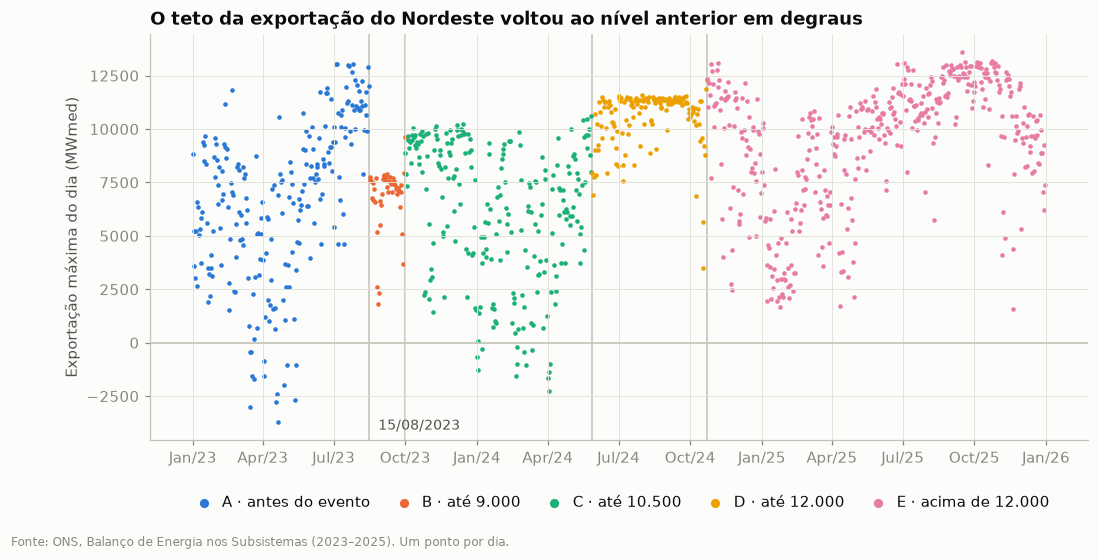

In [26]:
maximo_diario = ne["exportacao"].resample("D").max()
periodo_diario = ne["periodo"].resample("D").first()

fig, ax = plt.subplots(figsize=(11, 4.8))
for periodo in PERIODOS:
    serie = maximo_diario[periodo_diario == periodo]
    ax.scatter(serie.index, serie.values, s=9, color=CORES[periodo], label=periodo, linewidths=0)
for corte in CORTES:
    ax.axvline(corte, color=COR_EIXO, linewidth=1, zorder=0)
ax.annotate("15/08/2023", xy=(EVENTO, -3_900), xytext=(6, 0), textcoords="offset points",
            color=COR_SECUNDARIA, fontsize=9, va="center")
ax.axhline(0, color=COR_EIXO, linewidth=1)
ax.set_title("O teto da exportação do Nordeste voltou ao nível anterior em degraus")
ax.set_ylabel("Exportação máxima do dia (MWmed)")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b/%y"))
ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1),
          markerscale=2, handletextpad=0.2, columnspacing=1.2)
fig.text(0.01, -0.09, "Fonte: ONS, Balanço de Energia nos Subsistemas (2023–2025). Um ponto por dia.",
         color=COR_MUDA, fontsize=8)
plt.show()

**Interpretação.** Cada ponto é a maior exportação horária de um dia. Antes do evento, os máximos chegam a cerca de 13.000 MWmed. Logo depois, nenhum dia passa de 9.000; em seguida a faixa superior sobe em degraus, com períodos em que os máximos ficam alinhados numa linha quase horizontal. Esse alinhamento é o que se espera de um limite, e não de falta de vento, que produziria máximos dispersos.

### 6.4 Exportação e geração eólica + solar

A exportação depende de quanto o Nordeste gera.

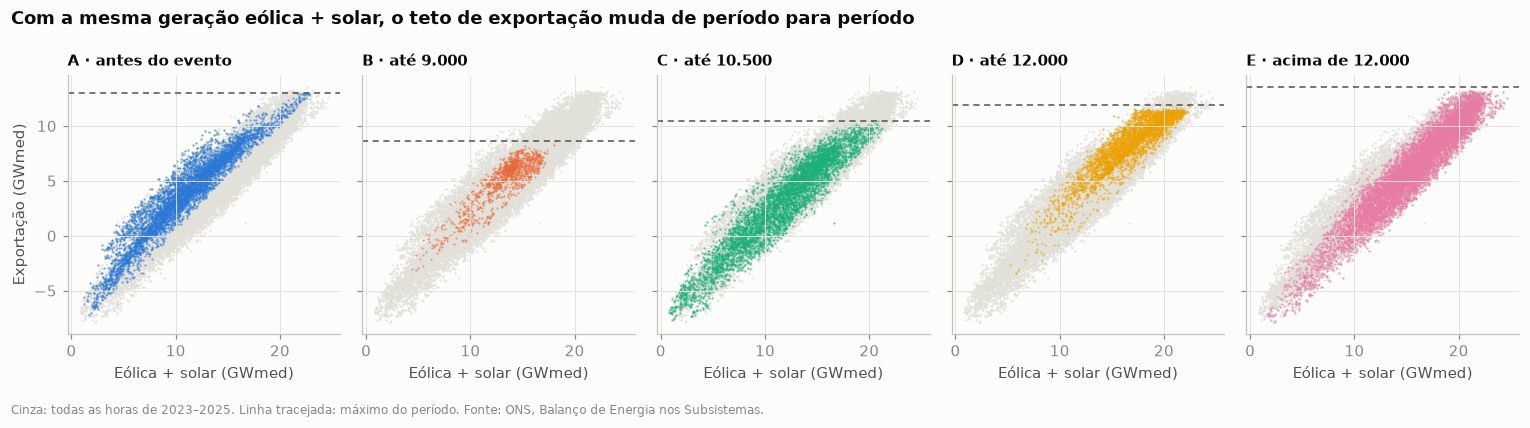

In [27]:
fig, eixos = plt.subplots(1, 5, figsize=(14, 3.6), sharex=True, sharey=True)
for ax, periodo in zip(eixos, PERIODOS):
    recorte = ne[ne["periodo"] == periodo]
    ax.scatter(ne["ger_eol_sol"] / 1000, ne["exportacao"] / 1000, s=2, color=COR_GRADE, linewidths=0, rasterized=True)
    ax.scatter(recorte["ger_eol_sol"] / 1000, recorte["exportacao"] / 1000, s=2, color=CORES[periodo],
               linewidths=0, alpha=0.6, rasterized=True)
    ax.axhline(recorte["exportacao"].max() / 1000, color=COR_SECUNDARIA, linewidth=1, linestyle=(0, (4, 3)))
    ax.set_title(periodo, fontsize=10)
    ax.set_xlabel("Eólica + solar (GWmed)")
eixos[0].set_ylabel("Exportação (GWmed)")
fig.suptitle("Com a mesma geração eólica + solar, o teto de exportação muda de período para período",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.text(0.01, -0.04, "Cinza: todas as horas de 2023–2025. Linha tracejada: máximo do período. "
         "Fonte: ONS, Balanço de Energia nos Subsistemas.", color=COR_MUDA, fontsize=8)
fig.tight_layout()
plt.show()

In [28]:
FAIXAS = [0, 8_000, 12_000, 16_000, 20_000, np.inf]
ROTULOS_FAIXA = ["até 8.000", "8.000–12.000", "12.000–16.000", "16.000–20.000", "acima de 20.000"]
ne["faixa_eol_sol"] = pd.cut(ne["ger_eol_sol"], FAIXAS, labels=ROTULOS_FAIXA)

por_faixa = ne.groupby(["faixa_eol_sol", "periodo"], observed=True)["exportacao"].agg(
    horas="size",
    mediana="median",
    p95=lambda s: s.quantile(0.95),
    maximo="max",
)
por_faixa.round(0).astype(int)

horas  mediana    p95  maximo
faixa_eol_sol   periodo                                           
até 8.000       A · antes do evento   1334     -858   2347    4260
                B · até 9.000           52     -527    962    1600
                C · até 10.500        1227    -2338    952    3768
                D · até 12.000          27     -300   1996    2249
                E · acima de 12.000    489    -3015    137    1672
8.000–12.000    A · antes do evento   1937     3294   6142    8456
                B · até 9.000          223     2536   4861    5627
                C · até 10.500        1578     1639   4524    7194
                D · até 12.000         253     3146   5368    6080
                E · acima de 12.000   1478     1600   4115    6043
12.000–16.000   A · antes do evento   1605     6399   8444   10500
                B · até 9.000          730     5960   7431    8191
                C · até 10.500        2137     5388   7720    9237
                D · até 12.000        1061     6747   8849   10930
                E · acima de 12.000   3078     4835   7446    9410
16.000–20.000   A · antes do evento    453     9087  10963   11810
                B · até 9.000           96     6867   7720    8589
                C · até 10.500         777     7932   9638   10203
                D · até 12.000        1652     9474  11173   11525
                E · acima de 12.000   3984     8572  11029   13083
acima de 20.000 A · antes do evento    103    11705  12939   13036
                C · até 10.500          43     9695  10229   10464
                D · até 12.000         559    10969  11408   11878
                E · acima de 12.000   1428    11230  12788   13592

## 7. Análise complementar: teste entre períodos

**Pergunta do teste.** Nas horas de geração eólica + solar alta, a exportação do período A (antes do evento) foi maior do que a dos períodos seguintes?

**Método.** Teste de Mann-Whitney aplicado dentro de cada faixa alta de geração, comparando A com cada período posterior. 

In [29]:
linhas = []
for faixa in ["16.000–20.000", "acima de 20.000"]:
    base = ne[ne["faixa_eol_sol"] == faixa]
    referencia = base.loc[base["periodo"] == PERIODOS[0], "exportacao"]
    for periodo in PERIODOS[1:]:
        comparado = base.loc[base["periodo"] == periodo, "exportacao"]
        if len(comparado) < 30:
            continue  # amostra pequena demais para comparar
        teste = stats.mannwhitneyu(referencia, comparado, alternative="greater")
        linhas.append({
            "faixa eólica + solar": faixa,
            "período comparado com A": periodo,
            "horas em A": len(referencia),
            "horas no período": len(comparado),
            "mediana A": referencia.median(),
            "mediana do período": comparado.median(),
            "diferença de medianas": referencia.median() - comparado.median(),
            "valor-p": teste.pvalue,
        })
testes = pd.DataFrame(linhas).set_index(["faixa eólica + solar", "período comparado com A"])
testes.style.format({"mediana A": "{:,.0f}", "mediana do período": "{:,.0f}",
                     "diferença de medianas": "{:,.0f}", "valor-p": "{:.2g}"})

**Interpretação.** Acima de 20.000 MWmed de eólica + solar, a mediana do período A supera a de C, D e E em 2.010, 736 e 474 MWmed. Na faixa de 16.000 a 20.000, A supera B e C (2.221 e 1.155 MWmed), mas não D: a mediana de D é 387 MWmed maior (valor-p = 1).

As maiores diferenças estão nos períodos de teto mais baixo (B e C), o que é compatível com a restrição. Mas E também fica abaixo de A, mesmo sem teto aparente, sinal de que outros fatores mudaram entre os períodos. A seção 8.2 separa essas parcelas.

### 7.1 Mesma estação em anos diferentes

Como controle adicional de sazonalidade, comparo setembro a dezembro de cada ano, meses que vêm logo depois do evento em 2023.

In [30]:
set_dez = ne[ne.index.month >= 9]
set_dez.groupby(set_dez.index.year).agg(
    exportacao_mediana=("exportacao", "median"),
    exportacao_p99=("exportacao", lambda s: s.quantile(0.99)),
    exportacao_maxima=("exportacao", "max"),
    eol_sol_mediana=("ger_eol_sol", "median"),
    eol_sol_p95=("ger_eol_sol", lambda s: s.quantile(0.95)),
).round(0).astype(int).rename_axis("ano (set–dez)")

,exportacao_mediana,exportacao_p99,exportacao_maxima,eol_sol_mediana,eol_sol_p95
ano (set–dez),,,,,
2023,5857,9781,10235,13964,18494
2024,7923,11917,13102,17250,21362
2025,8536,12950,13592,17536,21598


**Interpretação.** Entre setembro e dezembro de 2023, logo após o evento, a exportação máxima foi 10.235 MWmed, contra 13.102 em 2024 e 13.592 em 2025. A geração eólica + solar mediana, porém, também foi menor em 2023 (13.964 contra 17.250 e 17.536 MWmed), então parte da diferença pode vir de menos vento e sol. O controle é parcial: é compatível com um teto mais baixo em 2023, mas sozinho não o demonstra.

## 8. Modelo simples e decomposição do balanço

### 8.1 Decomposição exata da diferença em relação ao período A

Dentro de cada faixa alta de geração, a diferença de exportação média entre um período e o período A é igual à soma das diferenças de cada parcela do balanço. A primeira tabela mostra as médias de cada parcela; a segunda, a diferença de cada período em relação a A.

In [31]:
PARCELAS = ["ger_eol_sol", "val_gerhidraulica", "val_gertermica", "val_carga"]

medias = ne[ne["faixa_eol_sol"].isin(["16.000–20.000", "acima de 20.000"])].groupby(
    ["faixa_eol_sol", "periodo"], observed=True)[["exportacao"] + PARCELAS].mean()

medias.round(0).astype(int).rename(columns={
    "exportacao": "exportação", "ger_eol_sol": "eólica + solar", "val_gerhidraulica": "hidráulica",
    "val_gertermica": "térmica", "val_carga": "carga"})

exportação  eólica + solar  hidráulica  \
faixa_eol_sol   periodo                                                       
16.000–20.000   A · antes do evento        9153           17387        3236   
                B · até 9.000              6833           16504        2616   
                C · até 10.500             7887           17477        2915   
                D · até 12.000             9384           18017        3381   
                E · acima de 12.000        8519           17960        3018   
acima de 20.000 A · antes do evento       11741           21101        2538   
                C · até 10.500             9621           20411        2498   
                D · até 12.000            10849           20752        2474   
                E · acima de 12.000       11166           21055        2468   

                                     térmica  carga  
faixa_eol_sol   periodo                              
16.000–20.000   A · antes do evento      416  11887  
                B · até 9.000            351  12638  
                C · até 10.500           493  12998  
                D · até 12.000           877  12893  
                E · acima de 12.000      794  13254  
acima de 20.000 A · antes do evento      387  12285  
                C · até 10.500           441  13729  
                D · até 12.000           647  13024  
                E · acima de 12.000     1008  13365

In [32]:
linhas = []
for faixa in medias.index.get_level_values(0).unique():
    bloco = medias.loc[faixa]
    delta = bloco.sub(bloco.loc[PERIODOS[0]]).drop(index=PERIODOS[0])
    delta.insert(0, "faixa eólica + solar", faixa)
    linhas.append(delta.reset_index())
decomposicao = pd.concat(linhas).set_index(["faixa eólica + solar", "periodo"])
decomposicao["val_carga"] = -decomposicao["val_carga"]  # carga maior reduz a exportação
decomposicao.columns = ["Δ exportação", "Δ eólica + solar", "Δ hidráulica", "Δ térmica", "− Δ carga"]
decomposicao["conferência (soma das parcelas)"] = decomposicao.iloc[:, 1:].sum(axis=1)
decomposicao.round(0).astype(int)

Δ exportação  Δ eólica + solar  \
faixa eólica + solar periodo                                               
16.000–20.000        B · até 9.000               -2320              -883   
                     C · até 10.500              -1265                90   
                     D · até 12.000                231               630   
                     E · acima de 12.000          -634               573   
acima de 20.000      C · até 10.500              -2120              -690   
                     D · até 12.000               -892              -349   
                     E · acima de 12.000          -575               -46   

                                          Δ hidráulica  Δ térmica  − Δ carga  \
faixa eólica + solar periodo                                                   
16.000–20.000        B · até 9.000                -620        -66       -751   
                     C · até 10.500               -321         77      -1111   
                     D · até 12.000                145        461      -1006   
                     E · acima de 12.000          -218        378      -1367   
acima de 20.000      C · até 10.500                -39         54      -1444   
                     D · até 12.000                -64        260       -740   
                     E · acima de 12.000           -70        621      -1080   

                                          conferência (soma das parcelas)  
faixa eólica + solar periodo                                               
16.000–20.000        B · até 9.000                                  -2320  
                     C · até 10.500                                 -1265  
                     D · até 12.000                                   231  
                     E · acima de 12.000                             -634  
acima de 20.000      C · até 10.500                                 -2120  
                     D · até 12.000                                  -892  
                     E · acima de 12.000                             -575

**Interpretação.** Acima de 20.000 MWmed de eólica + solar, a exportação média do período C ficou 2.120 MWmed abaixo da do período A. Dessa diferença, 1.444 vêm de carga maior e 690 de geração eólica + solar menor dentro da própria faixa; hidráulica e térmica quase não mudam. A hidráulica média fica perto de 2.500 MWmed em todos os períodos nessa faixa, o que sugere que ela já está próxima do mínimo.

### 8.2 Regressão ajustada no período anterior ao evento

**Modelo.** `exportação = a + b · (eólica + solar) + c · carga`, por mínimos quadrados, comparado a uma referência só com eólica + solar.

**Validação.** Divisão temporal dentro do período A: treino até 14/06/2023, teste de 15/06 a 15/08/2023. Não há embaralhamento, para não usar o futuro na previsão do passado.

**Métricas.** Erro absoluto médio (MAE), erro médio (viés) e R² no teste.

In [33]:
def ajustar(dados, colunas):
    X = np.column_stack([np.ones(len(dados))] + [dados[c] for c in colunas])
    coeficientes, *_ = np.linalg.lstsq(X, dados["exportacao"], rcond=None)
    return coeficientes


def prever(dados, colunas, coeficientes):
    X = np.column_stack([np.ones(len(dados))] + [dados[c] for c in colunas])
    return pd.Series(X @ coeficientes, index=dados.index)


CORTE_TREINO = pd.Timestamp("2023-06-15")
periodo_a = ne[ne["periodo"] == PERIODOS[0]]
treino, teste = periodo_a[periodo_a.index < CORTE_TREINO], periodo_a[periodo_a.index >= CORTE_TREINO]

linhas = []
for nome, colunas in {"referência: eólica + solar": ["ger_eol_sol"],
                      "eólica + solar + carga": ["ger_eol_sol", "val_carga"]}.items():
    erro = teste["exportacao"] - prever(teste, colunas, ajustar(treino, colunas))
    linhas.append({
        "modelo": nome, "horas de treino": len(treino), "horas de teste": len(teste),
        "MAE (MWmed)": erro.abs().mean(), "viés (MWmed)": erro.mean(),
        "R²": 1 - (erro ** 2).sum() / ((teste["exportacao"] - teste["exportacao"].mean()) ** 2).sum(),
    })
pd.DataFrame(linhas).set_index("modelo").style.format(
    {"MAE (MWmed)": "{:,.0f}", "viés (MWmed)": "{:,.0f}", "R²": "{:.3f}"})

,horas de treino,horas de teste,MAE (MWmed),viés (MWmed),R²
modelo,,,,,
referência: eólica + solar,3960,1472,792,-601,0.871
eólica + solar + carga,3960,1472,810,-557,0.887


In [34]:
COLUNAS_MODELO = ["ger_eol_sol", "val_carga"]
coeficientes = ajustar(periodo_a, COLUNAS_MODELO)  # reajuste com todo o período A
ne["residuo_modelo"] = ne["exportacao"] - prever(ne, COLUNAS_MODELO, coeficientes)

print("Coeficientes (constante, eólica + solar, carga):", np.round(coeficientes, 3))
ne.groupby("periodo", observed=True)["residuo_modelo"].agg(
    media="mean", mediana="median", desvio_padrao="std").round(0).astype(int)

Coeficientes (constante, eólica + solar, carga): [-1.33708e+03  8.87000e-01 -3.90000e-01]


,media,mediana,desvio_padrao
periodo,,,
A · antes do evento,0,-214,1078
B · até 9.000,-568,-622,960
C · até 10.500,-808,-971,1288
D · até 12.000,-275,-630,1194
E · acima de 12.000,-1051,-1159,1138


## 9. Resumo

1. **O teto observado caiu logo após o evento.** Antes de 15/08/2023 a exportação chegou a 13.036 MWmed, com 36 horas acima de 12.000. Entre o evento e 30/09/2023 o máximo foi 8.590 MWmed.
2. **A recuperação ocorreu em degraus.** A exportação voltou a superar 9.000 MWmed em 30/09/2023, 10.500 em 27/05/2024 e 12.000 em 22/10/2024. Entre o evento e 22/10/2024 não houve nenhuma hora acima de 12.000.
3. **Os máximos ficaram alinhados durante os períodos restritos.** Em julho, agosto e setembro de 2024 os máximos mensais foram 11.606, 11.495 e 11.524 MWmed, padrão compatível com um limite.
4. **Nas horas de geração mais alta, a exportação foi menor nos períodos restritos, mas a maior parte da diferença de média vem da carga.** Acima de 20.000 MWmed de eólica + solar, o período C exportou em média 2.120 MWmed a menos que o período A; 1.444 vêm de carga maior e 690 de geração menor dentro da faixa (seção 8.2).
**Conclusão** Os máximos e as horas acima de limiares são compatíveis com um teto de exportação mais baixo após o evento, relaxado em três momentos e superado em 22/10/2024. As diferenças de média entre períodos são dominadas por carga e por despacho hidráulico e térmico, e não medem o teto. A base não permite afirmar a causa.

## 10. Limitações

- **Causa não observada.** A base não traz os limites operativos de intercâmbio. As datas dos patamares são inferidas dos dados e precisam ser confrontadas com documentos públicos do ONS.
- **Outros fatores mudaram.** A carga do Nordeste e a geração hidráulica também variaram entre os períodos, e ambas afetam a exportação sem relação com o limite.
- **Geração verificada, não disponível.** A base não informa a geração eólica e solar que estaria disponível sem restrição, então o corte de geração não é mensurável.

## 11. Próximos passos

1. Testar a sensibilidade dos cortes a outros limiares e ao uso do percentil 99 em vez do máximo.
2. Estimar, a partir de `teto + carga − hidráulica − térmica`, em quantas horas a geração eólica + solar verificada ficou encostada no limite implícito.
3. Detalhar em que horas do dia e meses o teto ficou ativo em cada período.

## Referências

- Operador Nacional do Sistema Elétrico (ONS). *Balanço de Energia nos Subsistemas*. Portal de Dados Abertos, recorte 2023–2025. Licença CC BY. Disponível em: https://dados.ons.org.br/dataset/balanco-energia-subsistema. 